# Batch correction with Harmony

`epi.tl.harmony` is a pure-Python port of the R **harmony** package (Korsunsky *et al.*, *Nat Methods* 2019), in the exact form ArchR runs it:

```r
set.seed(1)
proj <- addHarmony(proj, reducedDims = "IterativeLSI", groupBy = "Sample")
```

ArchR's `addHarmony` calls `harmony::RunHarmony` (harmony **1.2.4** here) on the iterative-LSI embedding and corrects it for the `Sample` covariate. The port follows harmony's C++ core line by line. It also replays R's own random number stream, used by the `stats::kmeans` (Hartigan–Wong, `nstart = 10`) centroid initialisation and by Armadillo's `shuffle` of the block-update order. So with the same `seed`, Epione returns **the same matrix as ArchR**, to floating-point round-off. No R, `rpy2`, `harmonypy` or `scanpy.external` is needed.

:::{note}
`scanpy.external.pp.harmony_integrate` is only a thin wrapper around the `harmonypy` package. `harmonypy` follows the original 2019 algorithm. harmony ≥ 1.0 changed several details: ridge-penalty λ handling, the block-update scheme, the convergence objective in single precision, and the k-means initialisation. Results from `harmonypy` therefore differ from what ArchR produces today. `epi.tl.harmony` targets harmony 1.2.4.
:::

This tutorial uses the ArchR Hematopoiesis tutorial data: 10,660 cells from three samples (BMMC, CD34⁺ BMMC and PBMC).


## Setup

In [1]:
import json, time, pathlib
import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
import epione as epi
from epione.pl._peak2gene import ARCHR_STALLION

epi.pl.plot_set(dpi=80)
FIXTURE = pathlib.Path('/scratch/users/steorra/analysis/25_epione/epione_dev/fixture')
REF = pathlib.Path('/scratch/users/steorra/analysis/25_epione/epione_dev/work/harmony/ref')

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



## Load the iterative-LSI embedding

`tables/lsi.tsv` is `getReducedDims(proj, "IterativeLSI")` exported from the ArchR project. That is the 30-dimensional, depth-filtered and scaled LSI that `addHarmony` feeds to harmony. `tables/cells.tsv` holds the cell metadata (`Sample`, ArchR `Clusters`).

In [2]:
lsi = pd.read_csv(FIXTURE / 'tables/lsi.tsv', sep='\t', index_col=0)
cells = pd.read_csv(FIXTURE / 'tables/cells.tsv', sep='\t', index_col=0).loc[lsi.index]

adata = ad.AnnData(np.zeros((lsi.shape[0], 0), dtype=np.float32), obs=cells[['Sample', 'Clusters', 'nFrags', 'TSSEnrichment']].copy())
adata.obsm['X_iterative_lsi'] = lsi.to_numpy()
for k in ['Sample', 'Clusters']:
    adata.obs[k] = pd.Categorical(adata.obs[k])
print(adata)
adata.obs['Sample'].value_counts()

AnnData object with n_obs × n_vars = 10660 × 0
    obs: 'Sample', 'Clusters', 'nFrags', 'TSSEnrichment'
    obsm: 'X_iterative_lsi'


Sample
scATAC_BMMC_R1         4932
scATAC_CD34_BMMC_R1    3275
scATAC_PBMC_R1         2453
Name: count, dtype: int64

## Run Harmony

Defaults mirror `addHarmony`/`RunHarmony`: `theta = 2`, `sigma = 0.1`, `lambda = 1`, `nclust = min(round(N / 30), 100)`, at most 10 rounds with early stopping. `seed` is the value you would pass to `set.seed()` in R.

In [3]:
%%time
epi.tl.harmony(adata, batch_key='Sample', use_rep='X_iterative_lsi', key_added='X_harmony', seed=1)
print(adata.obsm['X_harmony'].shape, '| rounds:', adata.uns['harmony']['n_iter'],
      '| k-means rounds per harmony round:', adata.uns['harmony']['kmeans_rounds'].tolist())

  └─ [harmony] 10660 cells, 30 dims, 3 batch levels, K=100


  └─ [harmony] converged after 3 iterations


(10660, 30) | rounds: 3 | k-means rounds per harmony round: [13, 9, 5]
CPU times: user 3.99 s, sys: 185 ms, total: 4.17 s
Wall time: 2.88 s


The objective (k-means error + entropy + diversity cross-entropy) is kept in float32, exactly as the C++ code does. Harmony stops once a round improves it by less than 1 %.

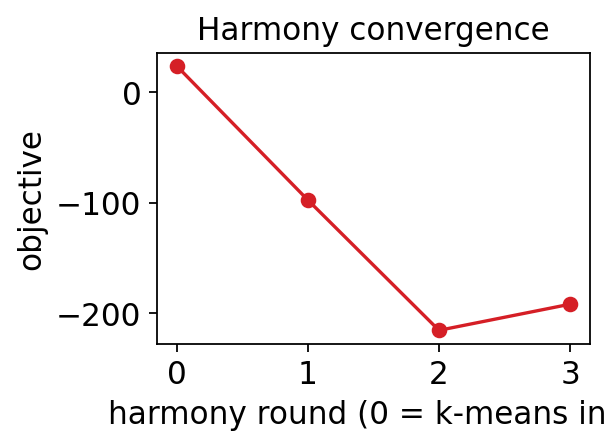

In [4]:
obj = adata.uns['harmony']['objective_harmony']
fig, ax = plt.subplots(figsize=(4, 3))
ax.plot(range(len(obj)), obj, 'o-', color='#D51F26')
ax.set_xlabel('harmony round (0 = k-means init)'); ax.set_ylabel('objective')
ax.set_title('Harmony convergence'); plt.tight_layout(); plt.show()

## UMAP before and after correction

Both UMAPs are computed with the same parameters (30 neighbours, cosine metric, `min_dist = 0.5`, as in ArchR's `addUMAP`).

In [5]:
%%time
for rep, key in [('X_iterative_lsi', 'X_umap_lsi'), ('X_harmony', 'X_umap_harmony')]:
    sc.pp.neighbors(adata, use_rep=rep, n_neighbors=30, metric='cosine', random_state=0, key_added=rep)
    epi.tl.umap(adata, min_dist=0.5, random_state=0, neighbors_key=rep)
    adata.obsm[key] = adata.obsm.pop('X_umap')

computing neighbors


    finished: added to `.uns['X_iterative_lsi']`
    `.obsp['X_iterative_lsi_distances']`, distances for each pair of neighbors
    `.obsp['X_iterative_lsi_connectivities']`, weighted adjacency matrix (0:00:25)


Computing UMAP embedding...


    Finished computing UMAP
    Added:
        'X_umap', UMAP coordinates (adata.obsm)
        'umap', UMAP parameters (adata.uns)
computing neighbors


    finished: added to `.uns['X_harmony']`
    `.obsp['X_harmony_distances']`, distances for each pair of neighbors
    `.obsp['X_harmony_connectivities']`, weighted adjacency matrix (0:00:02)


Computing UMAP embedding...


    Finished computing UMAP
    Added:
        'X_umap', UMAP coordinates (adata.obsm)
        'umap', UMAP parameters (adata.uns)
CPU times: user 44.7 s, sys: 992 ms, total: 45.7 s
Wall time: 45.4 s


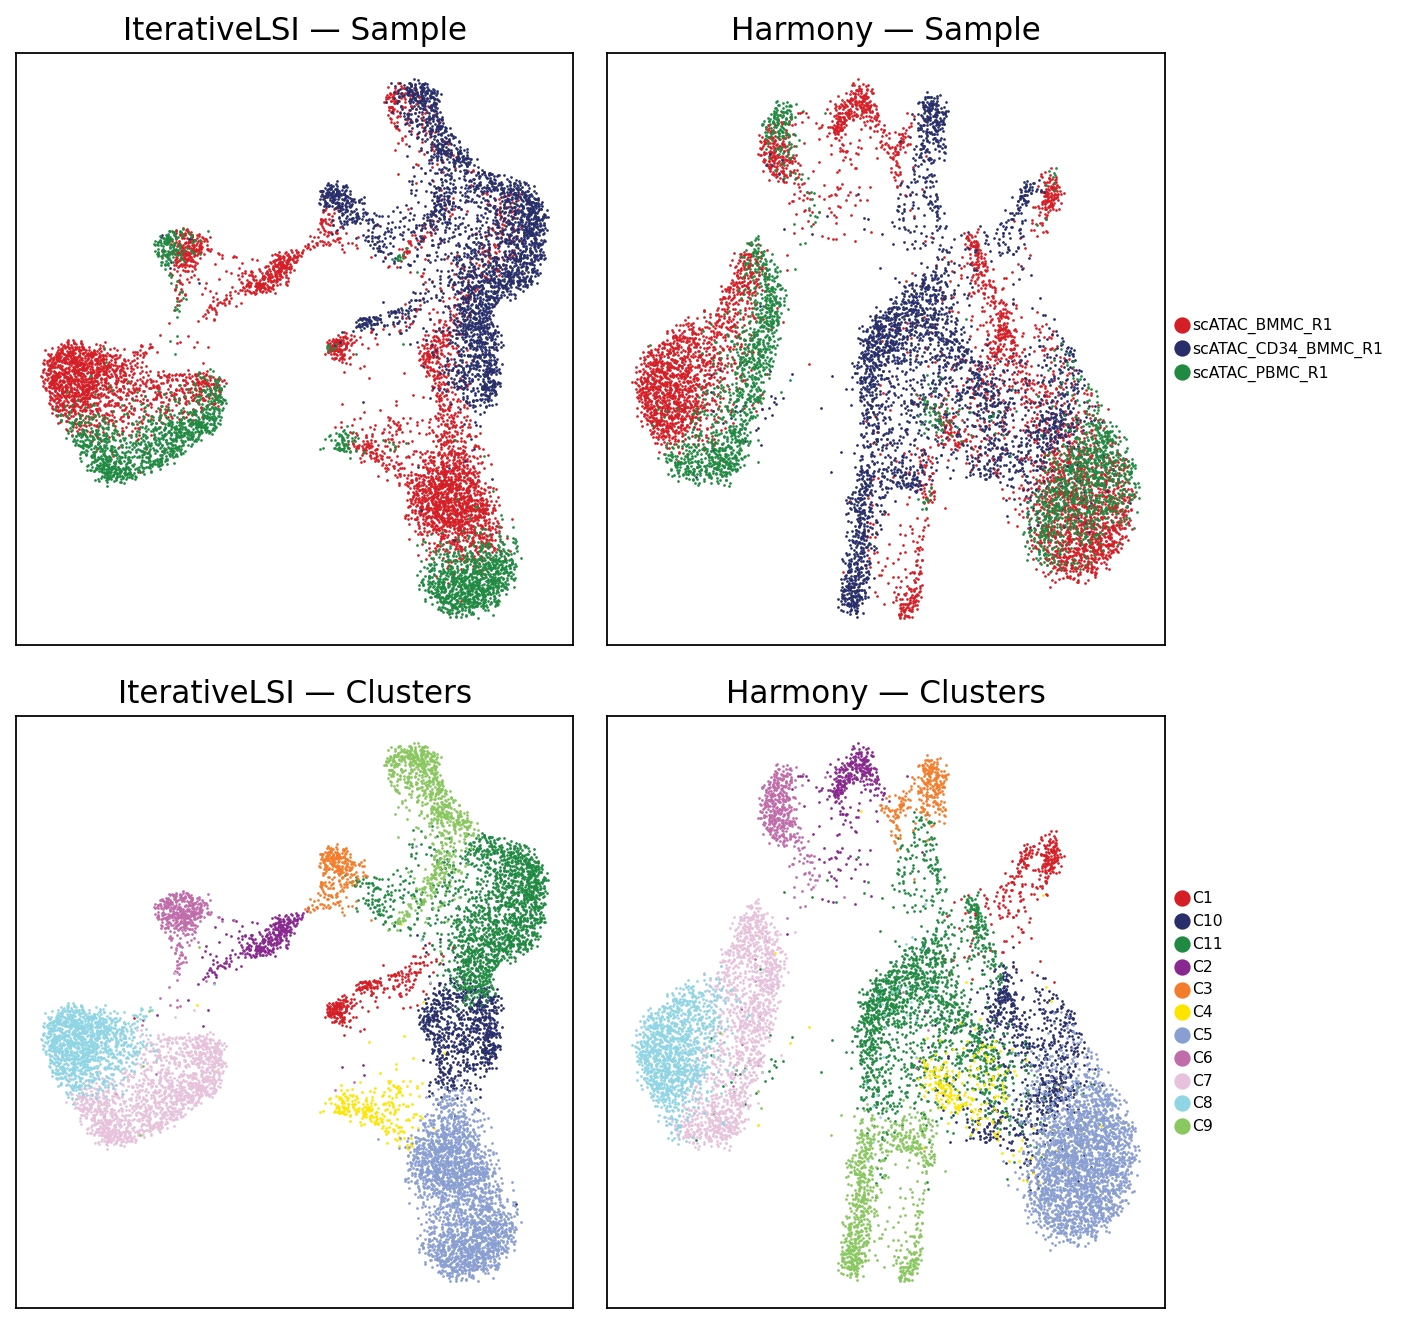

In [6]:
def archr_scatter(ax, xy, labels, title, palette):
    cats = labels.cat.categories
    for i, c in enumerate(cats):
        m = (labels == c).to_numpy()
        ax.scatter(xy[m, 0], xy[m, 1], s=1.5, color=palette[i % len(palette)], label=c, rasterized=True, linewidths=0)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title)

sample_pal = ['#D51F26', '#272E6A', '#208A42']
clust_pal = list(ARCHR_STALLION)
fig, axes = plt.subplots(2, 2, figsize=(9, 8.5))
for col, (key, name) in enumerate([('X_umap_lsi', 'IterativeLSI'), ('X_umap_harmony', 'Harmony')]):
    archr_scatter(axes[0, col], adata.obsm[key], adata.obs['Sample'], f'{name} — Sample', sample_pal)
    archr_scatter(axes[1, col], adata.obsm[key], adata.obs['Clusters'], f'{name} — Clusters', clust_pal)
axes[0, 1].legend(markerscale=6, fontsize=7, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))
axes[1, 1].legend(markerscale=6, fontsize=7, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5), ncol=1)
plt.tight_layout(); plt.show()

### How well are the samples mixed?

For each cell we take its 30 nearest neighbours in the embedding. Sample-mixing entropy is the Shannon entropy of the neighbours' sample labels, normalised to [0, 1]. Neighbourhood cluster purity is the fraction of neighbours that share the cell's ArchR cluster. Good integration raises mixing while keeping clusters intact. Here PBMC and BMMC share cell types, while the CD34⁺ progenitors are largely sample-specific, so mixing rises only where the biology overlaps.

In [7]:
from sklearn.neighbors import NearestNeighbors

def neighbourhood_stats(E, k=30):
    nn = NearestNeighbors(n_neighbors=k + 1).fit(E).kneighbors(E, return_distance=False)[:, 1:]
    s = adata.obs['Sample'].cat.codes.to_numpy(); c = adata.obs['Clusters'].cat.codes.to_numpy()
    n_s = len(adata.obs['Sample'].cat.categories)
    counts = np.stack([(s[nn] == j).sum(1) for j in range(n_s)], 1) / k
    with np.errstate(divide='ignore', invalid='ignore'):
        ent = -np.nansum(np.where(counts > 0, counts * np.log(counts), 0), 1) / np.log(n_s)
    return ent, (c[nn] == c[:, None]).mean(1)

rows = []
for rep in ['X_iterative_lsi', 'X_harmony']:
    ent, pur = neighbourhood_stats(adata.obsm[rep])
    adata.obs[f'mix_{rep}'] = ent
    rows.append({'embedding': rep, 'sample-mixing entropy (mean)': ent.mean(), 'cluster purity (mean)': pur.mean()})
pd.DataFrame(rows).set_index('embedding').round(3)

,sample-mixing entropy (mean),cluster purity (mean)
embedding,,
X_iterative_lsi,0.225,0.920
X_harmony,0.371,0.857


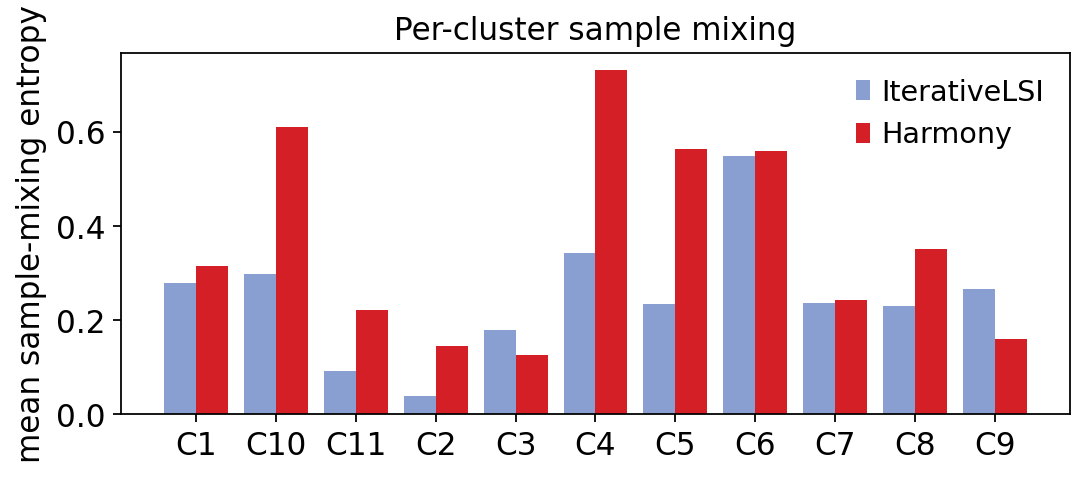

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
d = pd.DataFrame({'IterativeLSI': adata.obs['mix_X_iterative_lsi'], 'Harmony': adata.obs['mix_X_harmony'], 'Clusters': adata.obs['Clusters']})
m = d.groupby('Clusters', observed=True)[['IterativeLSI', 'Harmony']].mean()
x = np.arange(len(m)); w = 0.4
ax.bar(x - w/2, m['IterativeLSI'], w, label='IterativeLSI', color='#8A9FD1')
ax.bar(x + w/2, m['Harmony'], w, label='Harmony', color='#D51F26')
ax.set_xticks(x); ax.set_xticklabels(m.index, rotation=0); ax.set_ylabel('mean sample-mixing entropy')
ax.legend(frameon=False); ax.set_title('Per-cluster sample mixing'); plt.tight_layout(); plt.show()

## Parity vs ArchR

`tests/parity/harmony/ref_harmony.R` runs the reference in R and writes it to `REF`:

```bash
Rscript tests/parity/harmony/ref_harmony.R <ArchR project dir> <REF> 1
```

The script runs `set.seed(1); addHarmony(proj, reducedDims = "IterativeLSI", groupBy = "Sample")`. It then replays `RunHarmony` step by step, which reproduces `addHarmony` bit for bit, and dumps the k-means centroids, the R RNG state and every intermediate soft assignment `R` and corrected embedding `Z_corr`. `tests/parity/harmony/MANIFEST.md` pre-registers one gate per output, following the omicverse-rebuildr protocol.

In [9]:
archr = pd.read_csv(REF / 'archr_harmony.tsv.gz', sep='\t', index_col=0).loc[adata.obs_names]
H = adata.obsm['X_harmony']; A = archr.to_numpy()
diff = np.abs(H - A)
print(f'max |Epione - ArchR| = {diff.max():.3e}   (gate: 1e-8)')
print(f'Pearson r over all values = {np.corrcoef(H.ravel(), A.ravel())[0, 1]:.16f}')

max |Epione - ArchR| = 3.619e-13   (gate: 1e-8)
Pearson r over all values = 0.9999999999999994


In [10]:
import sys
sys.path.insert(0, str(pathlib.Path(epi.__file__).parents[1] / 'tests' / 'parity' / 'harmony'))
import parity_harmony as P

X = adata.obsm['X_iterative_lsi']; meta = adata.obs[['Sample']].astype(str)
rng = P.check_rng(REF, 1)
km = P.check_kmeans(REF, X, 1)
inj = P.check_injected(REF, X, meta)
free = P.check_free(REF, X, meta, 1, extended=True)

rows = [
    ('R RNG stream (runif, sample.int, .Random.seed)', 'deterministic-strict', 'exact', '0', 'identical' if all(rng.values()) else 'MISMATCH'),
    ('stats::kmeans centers (nstart=10)', 'deterministic', 'max abs err', '1e-8', f"{km['kmeans_centers_max_abs']:.1e}"),
    ('R after init (injected)', 'deterministic', 'max abs err', '1e-8', f"{inj['R_init_max_abs']:.1e}"),
]
for s in inj['iters']:
    rows.append((f"R / Z_corr after round {s['iter']} (injected)", 'deterministic', 'max abs err', '1e-8', f"{s['R_max_abs']:.1e} / {s['Zcorr_max_abs']:.1e}"))
rows += [
    ('k-means rounds per harmony round', 'exact', 'equality', '-', f"{inj['kmeans_rounds_py']} vs {inj['kmeans_rounds_r']}"),
    ('objective_harmony (float32)', 'deterministic, rtol', 'max rel err', '1e-6', f"{inj['objective_max_rel']:.1e}"),
    ('final embedding, free-running seed=1', 'deterministic', 'max abs err', '1e-8', f"{free['final_max_abs']:.1e}"),
    ('final embedding', 'embedding', 'Procrustes similarity', '>= 0.95', f"{free['procrustes_similarity']:.6f}"),
    ('30-NN graph', 'ranked', 'mean kNN Jaccard', '>= 0.95', f"{free['knn30_jaccard_mean']:.6f}"),
    ('Leiden clusters', 'clustering', 'ARI', '>= 0.95', f"{free['leiden_ari']:.6f}"),
]
pd.DataFrame(rows, columns=['output', 'class', 'metric', 'threshold', 'value'])

computing neighbors


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:06)


running Leiden clustering


    finished: found 10 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


computing neighbors


    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:01)


running Leiden clustering


    finished: found 10 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)


,output,class,metric,threshold,value
0,"R RNG stream (runif, sample.int, .Random.seed)",deterministic-strict,exact,0,identical
1,stats::kmeans centers (nstart=10),deterministic,max abs err,1e-8,8.9e-16
2,R after init (injected),deterministic,max abs err,1e-8,3.2e-15
3,R / Z_corr after round 1 (injected),deterministic,max abs err,1e-8,4.0e-15 / 3.7e-13
4,R / Z_corr after round 2 (injected),deterministic,max abs err,1e-8,3.2e-14 / 2.5e-13
5,R / Z_corr after round 3 (injected),deterministic,max abs err,1e-8,5.7e-14 / 4.0e-13
6,k-means rounds per harmony round,exact,equality,-,"[13, 9, 5] vs [13, 9, 5]"
7,objective_harmony (float32),"deterministic, rtol",max rel err,1e-6,1.6e-09
8,"final embedding, free-running seed=1",deterministic,max abs err,1e-8,3.6e-13
9,final embedding,embedding,Procrustes similarity,>= 0.95,1.000000


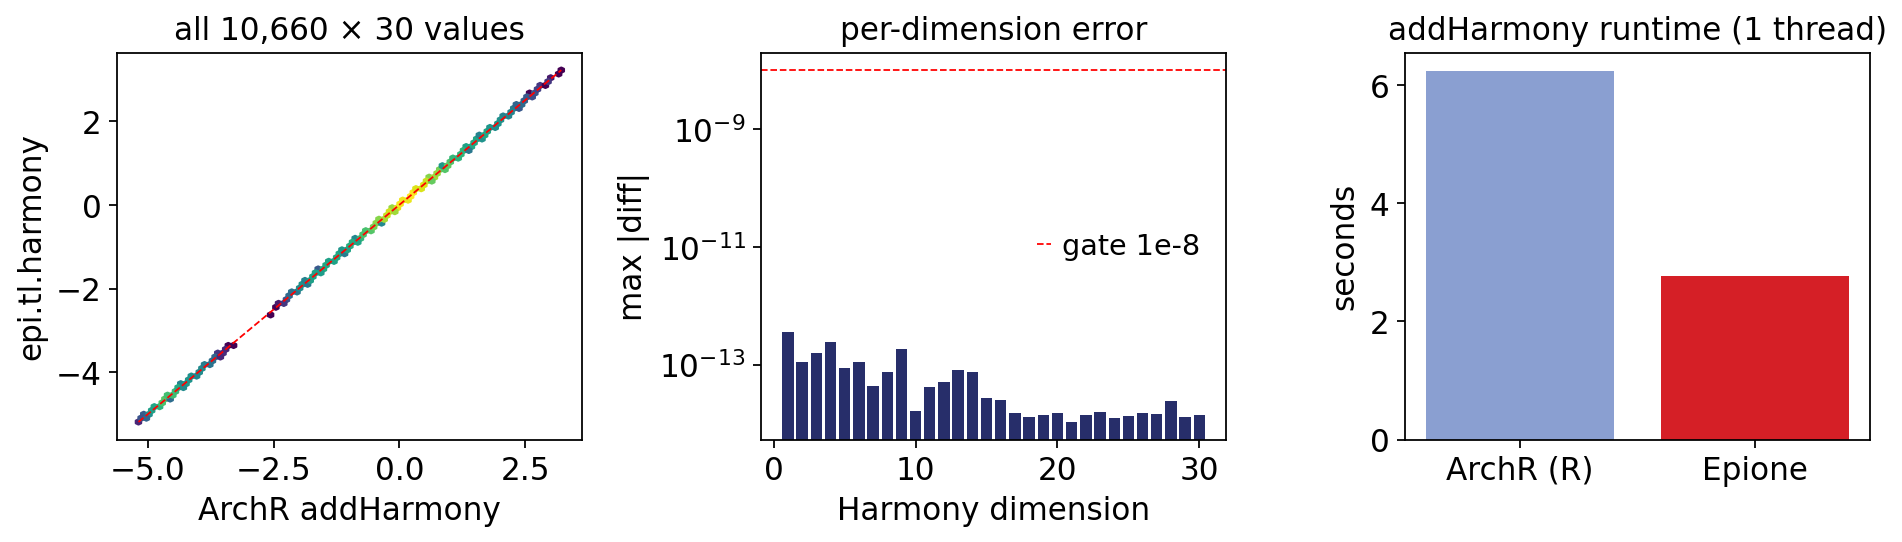

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
ax = axes[0]
ax.hexbin(A.ravel(), H.ravel(), gridsize=80, bins='log', cmap='viridis')
ax.plot([A.min(), A.max()], [A.min(), A.max()], 'r--', lw=0.8)
ax.set_xlabel('ArchR addHarmony'); ax.set_ylabel('epi.tl.harmony'); ax.set_title('all 10,660 × 30 values')
ax = axes[1]
ax.bar(np.arange(1, A.shape[1] + 1), diff.max(0), color='#272E6A')
ax.set_yscale('log'); ax.axhline(1e-8, color='r', ls='--', lw=0.8, label='gate 1e-8')
ax.set_xlabel('Harmony dimension'); ax.set_ylabel('max |diff|'); ax.legend(frameon=False); ax.set_title('per-dimension error')
ax = axes[2]
ax.bar(['ArchR (R)', 'Epione'], [free['archr_seconds'], free['python_seconds']], color=['#8A9FD1', '#D51F26'])
ax.set_ylabel('seconds'); ax.set_title('addHarmony runtime (1 thread)')
plt.tight_layout(); plt.show()

## Notes

* **Input.** ArchR feeds harmony `getReducedDims(proj, "IterativeLSI")`: the LSI after per-dimension scaling and removal of dimensions correlated (|r| > 0.75) with sequencing depth. Use the same matrix as `use_rep` for 1:1 results.
* **Several covariates.** Pass a list, e.g. `batch_key=['Sample', 'Donor']`. `theta` and `lambda_` then accept one value per covariate. `lambda_=None` switches on harmony's automatic λ estimation (`alpha * E`).
* **Factor levels.** Levels are taken in sorted order, as `as.factor()` does in R (or in category order for a pandas `Categorical`). Unused categories are dropped.
* **Matrix API.** `epi.tl.run_harmony(X, meta, vars_use)` mirrors `RunHarmony(data_mat, meta_data, vars_use)` and returns the corrected `cells × dims` matrix.
